# Homework 4:  KNN Classification and a Streamlit Application

**Student Name:**  Susan Peck

Name your homework ``.ipynb`` file using the following format un: ``firstname-lastname-hw4.ipynb``

##  Objective

In this assignment, you will develop and deploy a classification application using Python, scikit-learn, and Streamlit. You will use the Palmer Penguins dataset to predict a penguin's species from its physical measurements and other characteristics.

The classification question is:

> Can the species of a penguin be accurately predicted from its physical measurements and other available characteristics?

You will apply the following ideas from the KNN labs:

- Data cleaning and preprocessing
- Encoding categorical variables
- Training and test-data splitting
- Feature standardization
- K-nearest-neighbors classification
- Cross-validation for selecting $K$
- Confusion matrices and classification reports
- Building and publicly deploying a Streamlit application

## Dataset

For this homework, you will use the Palmer Penguins dataset. The data contain observations from three penguin species: Adélie, Chinstrap, and Gentoo. The dataset includes bill measurements, flipper length, body mass, island, sex, and year. The data is publicly available at the following links

- [Palmer Penguins project page](https://allisonhorst.github.io/palmerpenguins/)
- [GitHub repository](https://github.com/allisonhorst/palmerpenguins)
- [Direct CSV file](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv)

The target variable is:

```python
species
```

The possible target classes are `Adelie`, `Chinstrap`, and `Gentoo`. Do not use `species` as a predictor.

## Variables

| Variable | Description |
|---|---|
| `species` | Penguin species; target variable |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimeters |
| `bill_depth_mm` | Bill depth in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `sex` | Penguin sex |
| `year` | Year of observation |

**Use the following code to import the data and show the data head and tail**(1 points)

In [1]:
import pandas as pd

In [2]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

In [3]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [4]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


### 1. Obtain and describe the data (10 points)

Download the data from the given code below and report:

1. The number of observations and variables (2 points)
2. A description of each variable (2 points)
3. The target variable and its possible classes (2 points)
4. The number of observations in each class (2 points)
5. The number of missing values in each variable (2 points)



In [5]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

In [6]:
print(df.shape) # how many rows and columns of the data frame
print(df.dtypes) # the types of each of the variables
df.info() # any value less than the number of rows indicates missing values

(344, 8)
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


1.1 

The data frame contains 344 observations and 8 variables. Five of the variables are numeric (bill length, bill depth, flipper length, body mass, year), and three are string (species, island, sex). 

1.2 Description of each variable
- species: Penguin species (target variable). Three classes: Adelie, Chinstrap, Gentoo.
- island: Island where the penguin was observed. Categorical.
- bill_length_mm: Bill length in millimeters. Numeric.
- bill_depth_mm: Bill depth in millimeters. Numeric.
- flipper_length_mm: Flipper length in millimeters. Numeric.
- body_mass_g: Body mass in grams. Numeric.
- sex: Penguin sex. Categorical.
- year: Year of observation. Integer.

In [7]:
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

1.3 and 1.4

The target variable, species, has three classes. Adelie is the largest with 152 penguin observations, Gentoo with 124, and Chinstrap with 68. 

1.5

- species: 0 missing
- island: 0 missing
- bill_length_mm: 2 missing
- bill_depth_mm: 2 missing
- flipper_length_mm: 2 missing
- body_mass_g: 2 missing
- sex: 11 missing
- year: 0 missing

## 2. Clean and prepare the data (15 points)

You should:

- Handle missing values appropriately (3 points)
- Separate the predictors from the target (1 points)
- Encode categorical variables such as `island` and `sex` (3 points)
- Split the data into training and test sets (3 points)
- Use a stratified split (1 point).
- Standardize the predictors through a scikit-learn pipeline (4 points)

Use the test set only for final evaluation. Do not use it to choose $K$ or make other modeling decisions.

In [8]:
# Drop rows with any missing value (11 of 344 rows, about 3.2 percent)
df_clean = df.dropna()
print(df_clean.shape)

(333, 8)


In [9]:
# Target is species, observation year is dropped because it is not a physical characteristic
y = df_clean["species"]
X = df_clean.drop(columns=["species", "year"])

In [10]:
# Island dummy columns, Biscoe is the reference category
X = pd.get_dummies(X, columns=["island"], dtype=float, drop_first=True)

# Female coded 0 and male coded 1
X["sex_F_is_0"] = (X["sex"] == "male").astype(float)
X = X.drop(columns="sex")
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_F_is_0
0,39.1,18.7,181.0,3750.0,0.0,1.0,1.0
1,39.5,17.4,186.0,3800.0,0.0,1.0,0.0
2,40.3,18.0,195.0,3250.0,0.0,1.0,0.0
4,36.7,19.3,193.0,3450.0,0.0,1.0,0.0
5,39.3,20.6,190.0,3650.0,0.0,1.0,1.0


In [11]:
from sklearn.model_selection import train_test_split

# 70 percent training and 30 percent test, stratified by species
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101, stratify=y
)
print(X_train.shape, X_test.shape)

(233, 7) (100, 7)


In [12]:
# Species proportions in the full data, training set, and test set
props = pd.DataFrame({
    "Full": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
})
print(props.round(3))

            Full  Train  Test
species                      
Adelie     0.438  0.438  0.44
Gentoo     0.357  0.356  0.36
Chinstrap  0.204  0.206  0.20


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Scaler learns mean and standard deviation from training data only, K is tuned in Section 3
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30


### 3. Build and tune a KNN classifier (25 points)

#### 3.1 Model definition and selection of $K$ (10 points)

Construct a pipeline containing `StandardScaler` and `KNeighborsClassifier`. Investigate several values of $K$, such as $K=1,2,\ldots,30$.

Use five-fold cross-validation on the training data to select the value of $K$ that gives the best validation performance. Include a plot of cross-validation error rate versus $K$.



In [14]:
from sklearn.model_selection import cross_val_score

# Five-fold cross-validation error rate for K = 1 to 30, training data only
k_values = range(1, 31)
cv_errors = []

for k in k_values:
    # New pipeline for each K so scaling is fit inside each fold
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_errors.append(1 - scores.mean())

# Smallest K with the lowest error
best_k = list(k_values)[cv_errors.index(min(cv_errors))]
print(f"Selected K = {best_k}")
print(f"Smallest CV error = {min(cv_errors):.4f}")

Selected K = 2
Smallest CV error = 0.0000


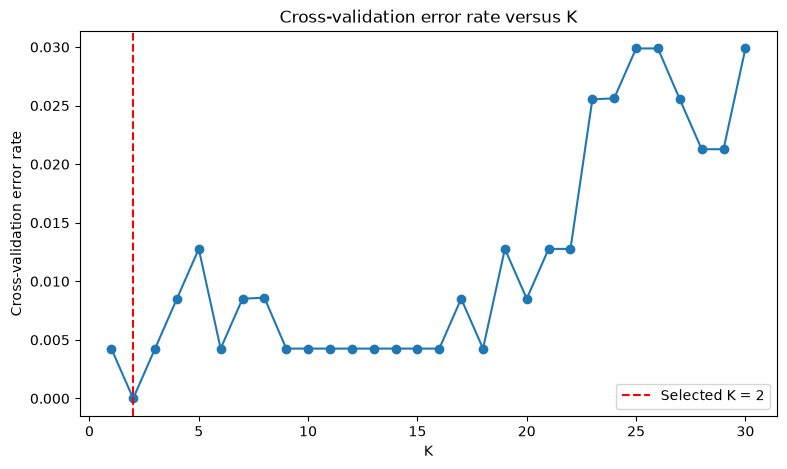

In [15]:
import matplotlib.pyplot as plt

# Cross-validation error rate versus K with the selected K marked
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), cv_errors, marker="o")
plt.axvline(best_k, color="red", linestyle="dashed", label=f"Selected K = {best_k}")
plt.xlabel("K")
plt.ylabel("Cross-validation error rate")
plt.title("Cross-validation error rate versus K")
plt.legend()
plt.show()

Five-fold cross-validation on the training data was run for K = 1 to 30. The lowest cross-validation error rate was 0.0000 at K = 2, so K = 2 is selected. Error rates were between 0 and 0.013 for every K up to 22, and between 0.021 and 0.030 for K = 23 to 30, so small values of K performed nearly the same and error rose for larger K.

#### 3.2 Importance of standardization and appropriate value of $K$ (5 points)

Explain why standardization is important for KNN and why a very small or very large value of $K$ may not perform well.

In [16]:
# CV error at the selected K with and without the scaler, training data only
scaled_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])
unscaled_model = KNeighborsClassifier(n_neighbors=best_k)

for name, model in [("With scaler", scaled_model), ("Without scaler", unscaled_model)]:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    print(f"{name}: CV error = {1 - scores.mean():.4f}")

With scaler: CV error = 0.0000
Without scaler: CV error = 0.2322


Standardization is important for KNN because the method classifies a penguin by its distance to other penguins, and distance is dominated by the variables with the largest numeric scale. Body mass is measured in thousands of grams, while bill depth is in the teens of millimeters, so without scaling body mass would dominate the distance and the other measurements would contribute very little. Standardizing gives every predictor a mean of 0 and a standard deviation of 1. At K = 2 the cross-validation error was 0.0000 with the scaler and 0.2322 without it.

A very small K bases each prediction on only one or two neighbors, so a single unusual penguin can change the result and the model follows noise in the training data (low bias, high variance). A very large K averages over many neighbors, so the decision boundaries become too smooth, real differences between species are missed, and the largest class gains influence over the vote (high bias, low variance). In these data the species are well separated, so very small K still performed well (error about 0.004 at K = 1), and the penalty for large K is the clearer effect (error about 0.030 at K = 30).

#### 3.3. Evaluate the final KNN model (10 points)

After selecting $K$, evaluate the final model on the test data. Report:

- Test accuracy (1 point)
- Test error rate (1 point)
- Confusion matrix (1 point)
- Precision, recall, and F1-score for each species (3 points)
- A written interpretation of the results (4 points)

In [17]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Fit the final pipeline with the selected K and predict the test set
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

In [18]:
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_accuracy:.4f}")

Test accuracy: 0.9900


In [19]:
print(f"Test error rate: {1 - test_accuracy:.4f}")

Test error rate: 0.0100


In [20]:
# Confusion matrix with species names, rows are true species and columns are predicted species
species_names = final_model.classes_
cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=species_names),
    index=[f"True {s}" for s in species_names],
    columns=[f"Predicted {s}" for s in species_names],
)
print(cm)

                Predicted Adelie  Predicted Chinstrap  Predicted Gentoo
True Adelie                   44                    0                 0
True Chinstrap                 1                   19                 0
True Gentoo                    0                    0                36


In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      Adelie       0.98      1.00      0.99        44
   Chinstrap       1.00      0.95      0.97        20
      Gentoo       1.00      1.00      1.00        36

    accuracy                           0.99       100
   macro avg       0.99      0.98      0.99       100
weighted avg       0.99      0.99      0.99       100



The final KNN model with K = 2 classified 99 of the 100 test penguins correctly, giving a test accuracy of 0.99 and a test error rate of 0.01. The confusion matrix shows a single error, one Chinstrap penguin predicted to be Adelie. All 44 Adelie penguins and all 36 Gentoo penguins were classified correctly. Precision was 0.98 for Adelie, 1.00 for Chinstrap, and 1.00 for Gentoo. Recall was 1.00 for Adelie, 0.95 for Chinstrap, and 1.00 for Gentoo, giving F1-scores of 0.99, 0.97, and 1.00. The lower Chinstrap recall and the lower Adelie precision both come from the one misclassified penguin, and Chinstrap has only 20 test penguins, so a single error moves its recall by 0.05.

These results show that penguin species can be predicted accurately from physical measurements, island, and sex. The test error of 0.01 is slightly higher than the cross-validation error of 0.0000, which is expected because the smallest cross-validation error was picked from 30 values of K. With only 100 test penguins, each additional error would change the accuracy by 0.01, so the estimates carry some uncertainty.

The single misclassified penguin was a tie. Its two nearest neighbors were one Adelie and one Chinstrap penguin, so the predicted probabilities were 0.5 for Adelie and 0.5 for Chinstrap, and scikit-learn broke the tie in favor of the species that comes first alphabetically, Adelie. Because K = 2 is even, ties like this can occur.

### 4. Streamlit application (50 points)

Create an interactive Streamlit application that allows a user to enter the characteristics of a new penguin and receive a predicted species.

The application must include:

- A title and short description of the project
- Input widgets for the predictor variables
- A button labeled **Predict Species**
- The predicted penguin species
- Predicted probabilities for the three classes
- The value of $K$ selected by cross-validation
- A brief explanation of the prediction

The dataset may be loaded directly from the public URL using:

```python
data_url = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/main/inst/extdata/penguins.csv"
)
df = pd.read_csv(data_url)
```

The app must be deployed publicly using [Streamlit Community Cloud](https://streamlit.io/cloud). Submit a public URL that opens without requiring the instructor to run the code locally.

####  Required submission files

Submit:

1. The Jupyter notebook used for the analysis
2. `app.py`, containing the Streamlit application
3. `requirements.txt`
4. A public GitHub repository link
5. A public Streamlit application link 
6. Any additional files required to run the application

Your GitHub repository should contain at least:

```text
penguin-classification/
├── app.py
├── requirements.txt
├── README.md
└── analysis.ipynb
```

### Submission links

- GitHub repository: https://github.com/susanpeck/penguin_classification
- Streamlit application: https://penguinclassification-knn.streamlit.app/

The GitHub repository contains `app.py`, `requirements.txt`, `README.md`, and `analysis.ipynb` (a copy of this notebook).